# Experiment 3: Data Cleaning and Preparation
## Problem Statement: Analyzing Customer Churn in a Telecommunications Company

**Dataset:** `Telecom_Customer_Churn.csv` (the uploaded Kaggle file, originally named `WA_Fn-UseC_-Telco-Customer-Churn.csv`).

**Objective:** Explore, clean, standardize, engineer useful features, prepare model-ready data, split it into training/testing sets, and export the results.

> This is the real Telco Customer Churn dataset (7,043 customer records), not the small synthetic sample shown in some practical references.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from pathlib import Path

DATA_PATH = Path("Telecom_Customer_Churn.csv")


## 2. Import the Dataset

In [2]:
df = pd.read_csv(DATA_PATH)
print("Dataset imported successfully")
print("Shape:", df.shape)
display(df.head())

Dataset imported successfully
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Explore the Dataset

In [3]:
print("Rows and columns:", df.shape)
print("\nColumn names:\n", df.columns.tolist())
print("\nDataset information:")
df.info()
print("\nNumerical summary:")
display(df.describe())
print("\nMissing values in each column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Rows and columns: (7043, 21)

Column names:
 ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000



Missing values in each column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0


## 4. Handle Missing Values and Correct Data Types
`TotalCharges` is stored as text in the source file. Blank/space-only values must first be converted to missing numeric values. For customers with tenure 0, a total charge of 0 is meaningful, so those blanks are filled with 0. Any remaining numeric missing values are filled with the median. Categorical missing values, if present, are filled with the mode.

In [4]:
# Remove extra spaces and convert blank strings to missing values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing values before treatment:")
print(df.isna().sum()[df.isna().sum() > 0])

# A customer with zero tenure has not accumulated monthly charges
zero_tenure = df["tenure"].eq(0)
df.loc[zero_tenure & df["TotalCharges"].isna(), "TotalCharges"] = 0

# Median for remaining numeric gaps; mode for categorical gaps
for col in df.select_dtypes(include=np.number).columns:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())
for col in df.select_dtypes(include="object").columns:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing values after treatment:", int(df.isna().sum().sum()))
print("TotalCharges type:", df["TotalCharges"].dtype)

Missing values before treatment:
TotalCharges    11
dtype: int64

Missing values after treatment: 0
TotalCharges type: float64


## 5. Remove Duplicate Records

In [5]:
rows_before = len(df)
duplicate_rows = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
# Customer ID is a unique identifier; keep the first record if an ID is repeated
duplicate_ids = int(df["customerID"].duplicated().sum())
df = df.drop_duplicates(subset="customerID", keep="first").copy()
print("Duplicate rows found:", duplicate_rows)
print("Repeated customer IDs found:", duplicate_ids)
print("Rows removed:", rows_before - len(df))
print("Shape after duplicate removal:", df.shape)

Duplicate rows found: 0
Repeated customer IDs found: 0
Rows removed: 0
Shape after duplicate removal: (7043, 21)


## 6. Standardize Inconsistent Data

In [6]:
# Normalize text formatting
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Standardize capitalization for categorical labels
df["gender"] = df["gender"].str.title()
for col in ["Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"]:
    df[col] = df[col].str.title()

print("Unique values after standardization:")
for col in df.select_dtypes(include="object").columns:
    if col != "customerID":
        print(col, ":", sorted(df[col].dropna().unique().tolist()))

Unique values after standardization:


gender : ['Female', 'Male']
Partner : ['No', 'Yes']
Dependents : ['No', 'Yes']
PhoneService : ['No', 'Yes']
MultipleLines : ['No', 'No phone service', 'Yes']
InternetService : ['DSL', 'Fiber optic', 'No']
OnlineSecurity : ['No', 'No internet service', 'Yes']
OnlineBackup : ['No', 'No internet service', 'Yes']
DeviceProtection : ['No', 'No internet service', 'Yes']
TechSupport : ['No', 'No internet service', 'Yes']
StreamingTV : ['No', 'No internet service', 'Yes']
StreamingMovies : ['No', 'No internet service', 'Yes']
Contract : ['Month-to-month', 'One year', 'Two year']
PaperlessBilling : ['No', 'Yes']
PaymentMethod : ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn : ['No', 'Yes']


## 7. Convert Columns to Correct Data Types

In [7]:
df["SeniorCitizen"] = df["SeniorCitizen"].astype("int64")
df["tenure"] = df["tenure"].astype("int64")
df["MonthlyCharges"] = df["MonthlyCharges"].astype("float64")
df["TotalCharges"] = df["TotalCharges"].astype("float64")
print(df.dtypes)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


## 8. Identify and Handle Outliers
Use boxplots and the IQR rule to flag unusual numerical values. An IQR flag does not automatically mean a value is wrong. Telecom charges and tenure can naturally be high; therefore, retain values that are within the dataset's valid business ranges. Only impossible values would be corrected or removed.

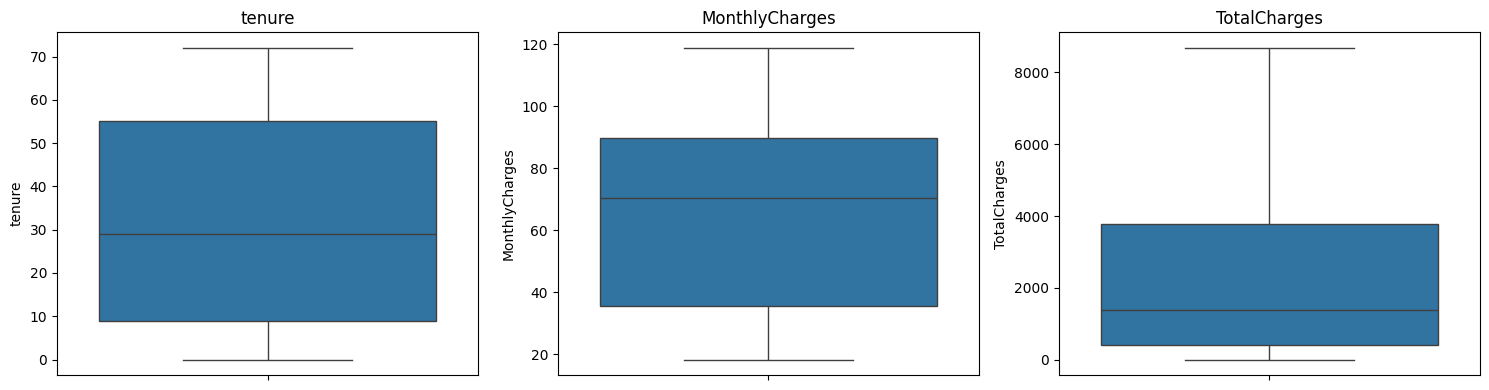

tenure: 0 IQR-flagged values (bounds: -60.00 to 124.00)
MonthlyCharges: 0 IQR-flagged values (bounds: -46.02 to 171.38)
TotalCharges: 0 IQR-flagged values (bounds: -4683.52 to 8868.67)
Impossible domain values: 0
Rows after domain validation: 7043


In [8]:
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((df[col] < lower) | (df[col] > upper)).sum())
    print(f"{col}: {count} IQR-flagged values (bounds: {lower:.2f} to {upper:.2f})")

# Domain checks: tenure 0-72 months; charges cannot be negative
invalid = (df["tenure"].lt(0) | df["tenure"].gt(72) |
           df["MonthlyCharges"].lt(0) | df["TotalCharges"].lt(0))
print("Impossible domain values:", int(invalid.sum()))
# Keep legitimate high values; remove only impossible records if any
df = df.loc[~invalid].copy()
print("Rows after domain validation:", len(df))

## 9. Feature Engineering
Create tenure groups, count the services subscribed to, and calculate average historical monthly spend. Convert churn to a binary target (Yes = 1, No = 0).

In [9]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["New (0-12 months)", "1-2 years", "2-4 years", "4-6 years"]
)
service_cols = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df["TotalServicesCount"] = df[service_cols].eq("Yes").sum(axis=1)
df["AvgMonthlySpend"] = np.where(
    df["tenure"] > 0, df["TotalCharges"] / df["tenure"], 0
)
df["Churn_Binary"] = df["Churn"].map({"No": 0, "Yes": 1}).astype(int)
display(df[["tenure", "TenureGroup", "TotalServicesCount", "AvgMonthlySpend", "Churn", "Churn_Binary"]].head())

,tenure,TenureGroup,TotalServicesCount,AvgMonthlySpend,Churn,Churn_Binary
0,1,New (0-12 months),1,29.850000,No,0
1,34,2-4 years,3,55.573529,No,0
2,2,New (0-12 months),3,54.075000,Yes,1
3,45,2-4 years,3,40.905556,No,0
4,2,New (0-12 months),1,75.825000,Yes,1


## 10. Encode and Scale Features; Split into Training and Testing Sets
Remove the customer ID and original text target from model inputs. One-hot encode categorical predictors. Split the data first; fit `StandardScaler` on the training set only to avoid data leakage, then transform the test set.

In [10]:
X = df.drop(columns=["customerID", "Churn", "Churn_Binary"])
y = df["Churn_Binary"]
X = pd.get_dummies(X, drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scale_cols = ["tenure", "MonthlyCharges", "TotalCharges", "TotalServicesCount", "AvgMonthlySpend"]
scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_test :", X_test.shape, " y_test :", y_test.shape)
print("Training churn rate:", round(y_train.mean(), 3))
print("Testing churn rate :", round(y_test.mean(), 3))
print("Training scaled means (approximately 0):")
print(X_train[scale_cols].mean().round(2))

X_train: (5634, 35)  y_train: (5634,)
X_test : (1409, 35)  y_test : (1409,)
Training churn rate: 0.265
Testing churn rate : 0.265
Training scaled means (approximately 0):
tenure               -0.0
MonthlyCharges       -0.0
TotalCharges          0.0
TotalServicesCount   -0.0
AvgMonthlySpend       0.0
dtype: float64


## 11. Export Cleaned Data and Model-Ready Splits

In [11]:
# Export human-readable cleaned data (keeps customerID and original Churn label)
df.to_csv("Cleaned_Telecom_Customer_Churn.csv", index=False)

# Export model-ready train/test features and labels
X_train.to_csv("X_train.csv", index=False)
X_test.to_csv("X_test.csv", index=False)
y_train.to_frame("Churn_Binary").to_csv("y_train.csv", index=False)
y_test.to_frame("Churn_Binary").to_csv("y_test.csv", index=False)

print("Exported: Cleaned_Telecom_Customer_Churn.csv, X_train.csv, X_test.csv, y_train.csv, y_test.csv")

Exported: Cleaned_Telecom_Customer_Churn.csv, X_train.csv, X_test.csv, y_train.csv, y_test.csv


## 12. Final Verification and Conclusion

In [12]:
print("Final cleaned dataset shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Duplicate customer IDs:", int(df["customerID"].duplicated().sum()))
print("Churn distribution:")
print(df["Churn"].value_counts())
display(df.head())

print("\nConclusion:")
print("The telecom dataset was explored, cleaned, standardized and converted to suitable data types.")
print("Valid extreme values were retained after domain checks. New customer features were created.")
print("Categorical variables were encoded, numerical features were scaled using training data only,")
print("and the data was split into training and testing sets for future churn modeling.")

Final cleaned dataset shape: (7043, 25)
Missing values: 0
Duplicate rows: 0
Duplicate customer IDs: 0
Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup,TotalServicesCount,AvgMonthlySpend,Churn_Binary
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,New (0-12 months),1,29.850000,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,2-4 years,3,55.573529,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,New (0-12 months),3,54.075000,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,2-4 years,3,40.905556,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,New (0-12 months),1,75.825000,1



Conclusion:
The telecom dataset was explored, cleaned, standardized and converted to suitable data types.
Valid extreme values were retained after domain checks. New customer features were created.
Categorical variables were encoded, numerical features were scaled using training data only,
and the data was split into training and testing sets for future churn modeling.
